# Auditoría y Evaluación de Desempeño de FinBERT a Gran Escala ($N = 600$)
## Benchmark frente a Ground Truth: Arquitectura S0B (Ventana 0 + Poda) vs S1B (Ventana $\pm 1$)
**Proyecto:** TFM Data Science — NLP Financiero y Predicción de Sentimiento Bancario  
**Objetivo Científico:** Evaluar formalmente el desempeño de clasificación (*Accuracy*, *Recall*, *Matriz de Confusión*, *Inversiones Graves*) del modelo FinBERT sobre un corpus representativo de **600 artículos financieros** contrastándolo contra el **Ground Truth Experto** ($N = 600$), validando si la eliminación del boilerplate y la reducción a la ventana oracional exacta ($S0B$) mitiga el sesgo de contagio sintáctico sin degradar la precisión.


In [14]:
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración de rutas del proyecto
PROJ_ROOT = Path('.').resolve()
if not (PROJ_ROOT / 'scratch').exists():
    for parent in PROJ_ROOT.parents:
        if (parent / 'scratch').exists():
            PROJ_ROOT = parent
            break

csv_600_path = PROJ_ROOT / 'scratch' / 'finbert_pilot_v2_revision600_ventana_0.csv'
print(f'[OK] Raíz del proyecto: {PROJ_ROOT}')
print(f'[OK] Dataset auditado con Ground Truth: {csv_600_path}')


[OK] Raíz del proyecto: C:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master
[OK] Dataset auditado con Ground Truth: C:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\scratch\finbert_pilot_v2_revision600_ventana_0.csv


## 1. Carga del Dataset y Validación de la Distribución del Ground Truth ($N = 600$)
Cargamos los 600 artículos con sus predicciones continuas de FinBERT ($S0B$ y $S1B$) y la etiqueta objetiva de referencia (`gt_sentiment`) generada bajo aislamiento de entidad.


In [15]:
df_600 = pd.read_csv(csv_600_path)
print(f'Total de noticias cargadas: {len(df_600)}')
print(f'Columnas: {list(df_600.columns)}')

mapa_etiquetas = {1: 'Positivo (+1)', 0: 'Neutral (0)', -1: 'Negativo (-1)'}

# Distribución del Ground Truth
dist_gt = df_600['gt_sentiment'].map(mapa_etiquetas).value_counts()
df_dist_gt = pd.DataFrame({
    'Noticias GT': dist_gt,
    'Porcentaje (%)': (100 * dist_gt / len(df_600)).round(1)
}).loc[['Positivo (+1)', 'Neutral (0)', 'Negativo (-1)']]

print('\n=== DISTRIBUCIÓN DEL GROUND TRUTH (VERDAD OBJETIVA N = 600) ===')
display(df_dist_gt)

# Desglose de distribución de artículos por entidad bancaria
print('\n=== DISTRIBUCIÓN POR BANCO ===')
display(df_600['ticker'].value_counts().to_frame('Total Artículos'))


Total de noticias cargadas: 600
Columnas: ['ticker', 'titular', 'longitud_cuerpo_caracteres', 'S0B_texto', 'S0B_tokens', 'S0B_localizado', 'S0B_sentiment', 'S0B_confidence', 'S0B_pos', 'S0B_neg', 'S0B_neu', 'S1B_sentiment', 'S1B_confidence', 'gt_sentiment', 'gt_reason']

=== DISTRIBUCIÓN DEL GROUND TRUTH (VERDAD OBJETIVA N = 600) ===


,Noticias GT,Porcentaje (%)
gt_sentiment,,
Positivo (+1),181,30.2
Neutral (0),295,49.2
Negativo (-1),124,20.7



=== DISTRIBUCIÓN POR BANCO ===


,Total Artículos
ticker,
WFC,176
GS,176
C,138
MS,108
JPM,2


## 2. Métricas de Desempeño: ¿Cómo Clasificó FinBERT (Bien vs Mal)?
Discretizamos las puntuaciones continuas de FinBERT ($[-1.0, +1.0]$) con el umbral financiero $|S| > 0.15$ para comparar el rendimiento de:
* **$S1B$ (Ventana Tradicional $\pm 1$ + Poda)**
* **$S0B$ (Ventana Focalizada 0 + Poda)** frente al Ground Truth.


In [16]:
def discretizar(s: pd.Series, umbral: float = 0.15) -> pd.Series:
    """Mapea polaridad continua a clases discretas {-1, 0, +1}."""
    return s.apply(lambda x: 1 if x > umbral else (-1 if x < -umbral else 0))

df_600['S0B_pred'] = discretizar(df_600['S0B_sentiment'])
df_600['S1B_pred'] = discretizar(df_600['S1B_sentiment'])
y_true = df_600['gt_sentiment']

# 1. Cálculo de Métricas Globales
def calcular_kpis(y_pred, y_real, nombre):
    acc = (y_pred == y_real).mean()
    rec_pos = (y_pred[y_real == 1] == 1).mean() if (y_real == 1).sum() > 0 else 0
    rec_neg = (y_pred[y_real == -1] == -1).mean() if (y_real == -1).sum() > 0 else 0
    rec_neu = (y_pred[y_real == 0] == 0).mean() if (y_real == 0).sum() > 0 else 0
    
    # Inversiones Graves (+1 predicho como -1 o viceversa)
    inv = (((y_real == 1) & (y_pred == -1)) | ((y_real == -1) & (y_pred == 1))).sum()
    
    return {
        'Estrategia': nombre,
        'Accuracy Global': acc,
        'Recall Positivo (+1)': rec_pos,
        'Recall Negativo (-1)': rec_neg,
        'Recall Neutral (0)': rec_neu,
        'Inversiones Graves': inv,
        'Tasa Inversión (%)': round(100 * inv / len(y_real), 1)
    }

res_s1b = calcular_kpis(df_600['S1B_pred'], y_true, 'S1B (Ventana ±1 + Poda)')
res_s0b = calcular_kpis(df_600['S0B_pred'], y_true, 'S0B (Ventana 0 + Poda) [Final]')

df_kpis = pd.DataFrame([res_s1b, res_s0b])
print('=== CUADRO COMPARATIVO OFICIAL DE DESEMPEÑO FRENTE A GROUND TRUTH (N = 600) ===')
display(df_kpis.round(3))


=== CUADRO COMPARATIVO OFICIAL DE DESEMPEÑO FRENTE A GROUND TRUTH (N = 600) ===


,Estrategia,Accuracy Global,Recall Positivo (+1),Recall Negativo (-1),Recall Neutral (0),Inversiones Graves,Tasa Inversión (%)
0,S1B (Ventana ±1 + Poda),0.562,0.635,0.895,0.376,60,10.0
1,S0B (Ventana 0 + Poda) [Final],0.570,0.696,0.871,0.366,44,7.3


## 3. Matrices de Confusión Reales (FinBERT vs Ground Truth)
Inspeccionamos detalladamente dónde acierta y dónde comete errores cada variante de FinBERT al contrastarla con la realidad financiera.


In [17]:
orden_clases = ['Positivo (+1)', 'Neutral (0)', 'Negativo (-1)']

# Matriz de Confusión S0B vs Ground Truth
cm_s0b = pd.crosstab(
    y_true.map(mapa_etiquetas),
    df_600['S0B_pred'].map(mapa_etiquetas),
    rownames=['Ground Truth (Real)'],
    colnames=['Predicción S0B']
).reindex(index=orden_clases, columns=orden_clases, fill_value=0)

# Matriz de Confusión S1B vs Ground Truth
cm_s1b = pd.crosstab(
    y_true.map(mapa_etiquetas),
    df_600['S1B_pred'].map(mapa_etiquetas),
    rownames=['Ground Truth (Real)'],
    colnames=['Predicción S1B']
).reindex(index=orden_clases, columns=orden_clases, fill_value=0)

print('=== MATRIZ DE CONFUSIÓN: FINBERT S0B (VENTANA 0) FRENTE A GROUND TRUTH ===')
display(cm_s0b)

print('\n=== MATRIZ DE CONFUSIÓN: FINBERT S1B (VENTANA ±1) FRENTE A GROUND TRUTH ===')
display(cm_s1b)


=== MATRIZ DE CONFUSIÓN: FINBERT S0B (VENTANA 0) FRENTE A GROUND TRUTH ===


Predicción S0B,Positivo (+1),Neutral (0),Negativo (-1)
Ground Truth (Real),,,
Positivo (+1),126,21,34
Neutral (0),87,108,100
Negativo (-1),10,6,108



=== MATRIZ DE CONFUSIÓN: FINBERT S1B (VENTANA ±1) FRENTE A GROUND TRUTH ===


Predicción S1B,Positivo (+1),Neutral (0),Negativo (-1)
Ground Truth (Real),,,
Positivo (+1),115,16,50
Neutral (0),76,111,108
Negativo (-1),10,3,111


## 4. Eficiencia de Cómputo y Desacoplamiento de Tokens en $S0B$
Analizamos el consumo de tokens y comprobamos cómo la reducción a la ventana exacta protege el presupuesto computacional sin truncar el contexto.


In [18]:
desc_tok = df_600['S0B_tokens'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
df_stats_tokens = pd.DataFrame({
    'Métrica': ['Media', 'Desv. Típica', 'Mínimo', 'P25 (Q1)', 'Mediana (P50)', 'P75 (Q3)', 'P90', 'P95', 'P99', 'Máximo'],
    'Tokens S0B': [
        desc_tok['mean'], desc_tok['std'], desc_tok['min'],
        desc_tok['25%'], desc_tok['50%'], desc_tok['75%'],
        desc_tok['90%'], desc_tok['95%'], desc_tok['99%'],
        desc_tok['max']
    ]
}).round(1)

display(df_stats_tokens)

corr_len = df_600['longitud_cuerpo_caracteres'].corr(df_600['S0B_tokens'])
print(f'\n[DESACOPLAMIENTO ESTRUCTURAL]')
print(f'• Correlación (Longitud Documento vs Tokens S0B): r = {corr_len:.3f}')
print(f'• Artículos dentro de 256 tokens: {(df_600["S0B_tokens"] <= 256).mean()*100:.1f}%')
print(f'• Artículos dentro de 512 tokens: {(df_600["S0B_tokens"] <= 512).mean()*100:.1f}%')


,Métrica,Tokens S0B
0,Media,125.1
1,Desv. Típica,96.0
2,Mínimo,16.0
3,P25 (Q1),62.0
4,Mediana (P50),86.0
5,P75 (Q3),161.0
6,P90,266.0
7,P95,343.0
8,P99,437.2
9,Máximo,596.0



[DESACOPLAMIENTO ESTRUCTURAL]
• Correlación (Longitud Documento vs Tokens S0B): r = 0.078
• Artículos dentro de 256 tokens: 88.8%
• Artículos dentro de 512 tokens: 99.3%


## 5. Inspección Cualitativa: Casos Reales Resueltos por $S0B$ frente a $S1B$
Mostramos ejemplos empíricos donde $S1B$ cometía un error grave por contagio y $S0B$ acertó en concordancia con el Ground Truth.


In [19]:
# Artículos donde S1B invirtió (-1) pero el Ground Truth era (+1) y S0B acertó (+1)
casos_exito = df_600[(df_600['gt_sentiment'] == 1) & (df_600['S1B_pred'] == -1) & (df_600['S0B_pred'] == 1)].head(3)

print('=== CASOS REALES DE RESCATE: S1B FALLA POR CONTAGIO -> S0B ACIERTA CON GROUND TRUTH ===')
for idx, r in casos_exito.iterrows():
    print('=' * 85)
    print(f'Fila {idx:03d} [{r["ticker"]}] | Ground Truth: {mapa_etiquetas[r["gt_sentiment"]]}')
    print(f'  • FinBERT S1B (±1): {r["S1B_sentiment"]:+.2f} ({mapa_etiquetas[r["S1B_pred"]]}) -> ERROR GRAVE')
    print(f'  • FinBERT S0B (0):  {r["S0B_sentiment"]:+.2f} ({mapa_etiquetas[r["S0B_pred"]]}) -> ACIERTO')
    print(f'Titular: {r["titular"][:85]}...')
    print(f'Criterio Experto: {r["gt_reason"]}')
    print(f'Texto que leyó S0B: {r["S0B_texto"][:180]}...\n')


=== CASOS REALES DE RESCATE: S1B FALLA POR CONTAGIO -> S0B ACIERTA CON GROUND TRUTH ===
Fila 027 [C] | Ground Truth: Positivo (+1)
  • FinBERT S1B (±1): -0.53 (Negativo (-1)) -> ERROR GRAVE
  • FinBERT S0B (0):  +0.92 (Positivo (+1)) -> ACIERTO
Titular: 3 Bank Stocks Cheaper Than Bank of America Corp....
Criterio Experto: Bullish stock analysis highlighting Citigroup's 26% YoY rise in global consumer banking net income, international growth, expense cuts, and discounted valuation.
Texto que leyó S0B: 3 Bank Stocks Cheaper Than Bank of America Corp. [SEP] No. 3: Citigroup
If any bank can truly sympathize with what Bank of America has gone through since 2009, it's Citigroup. In o...

Fila 033 [C] | Ground Truth: Positivo (+1)
  • FinBERT S1B (±1): -0.89 (Negativo (-1)) -> ERROR GRAVE
  • FinBERT S0B (0):  +0.50 (Positivo (+1)) -> ACIERTO
Titular: Citigroup (C) Q3 Earnings Beat on Low Costs & High Revenues...
Criterio Experto: Citigroup delivered a 7.6% Q3 earnings beat, cut operating exp

## 6. Dashboard Gráfico Consolidado ($N = 600$)
Visualización de 4 paneles con estilo visual académico para la memoria del TFM.


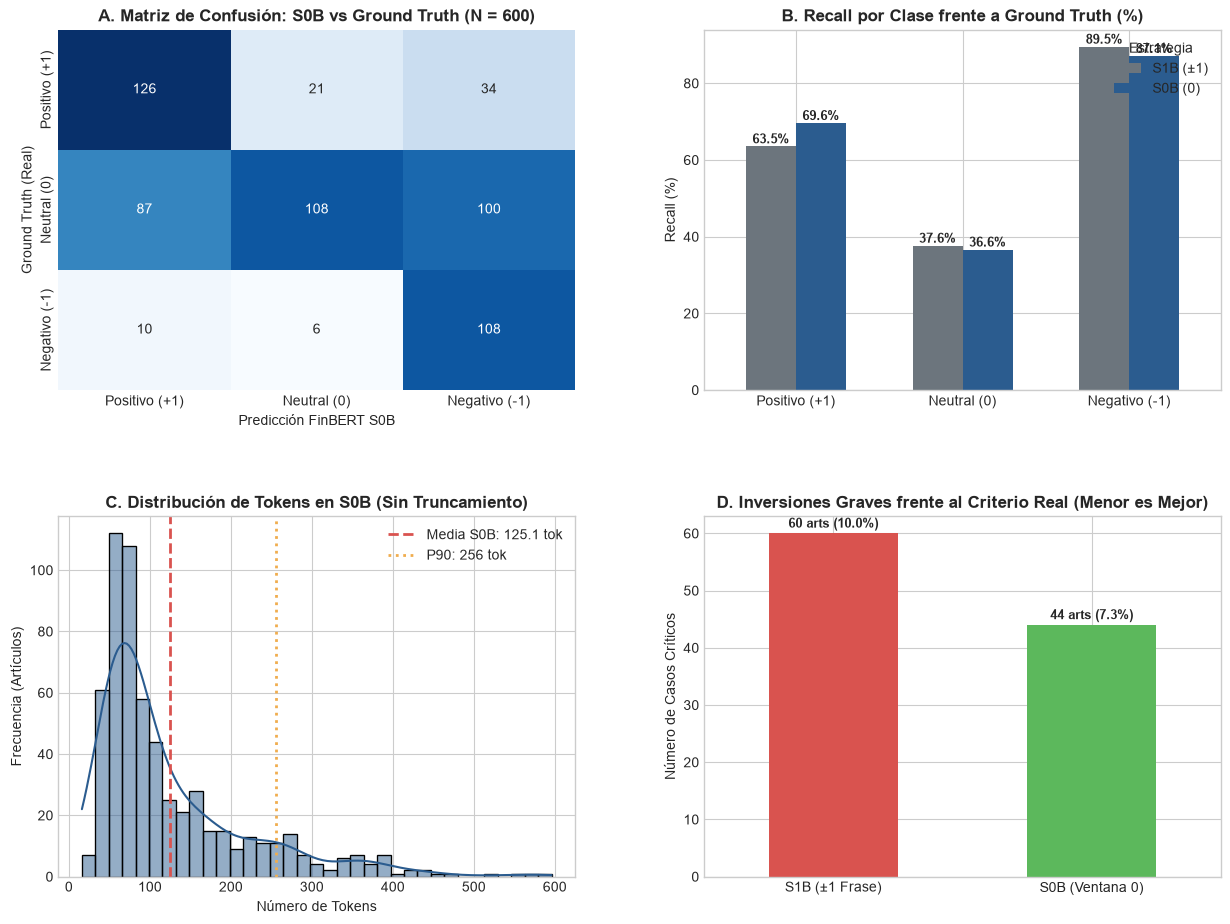

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Panel A: Matriz de Confusión S0B vs Ground Truth
ax1 = axes[0, 0]
sns.heatmap(cm_s0b, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('A. Matriz de Confusión: S0B vs Ground Truth (N = 600)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Predicción FinBERT S0B')
ax1.set_ylabel('Ground Truth (Real)')

# Panel B: Comparativa de Recall por Clase
ax2 = axes[0, 1]
df_recalls = pd.DataFrame({
    'S1B (±1)': [res_s1b['Recall Positivo (+1)'], res_s1b['Recall Neutral (0)'], res_s1b['Recall Negativo (-1)']],
    'S0B (0)': [res_s0b['Recall Positivo (+1)'], res_s0b['Recall Neutral (0)'], res_s0b['Recall Negativo (-1)']]
}, index=['Positivo (+1)', 'Neutral (0)', 'Negativo (-1)']) * 100

df_recalls.plot(kind='bar', color=['#6c757d', '#2b5c8f'], ax=ax2, width=0.6)
ax2.set_title('B. Recall por Clase frente a Ground Truth (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Recall (%)')
ax2.set_xticklabels(df_recalls.index, rotation=0)
ax2.legend(title='Estrategia', loc='upper right')
for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 0.8),
                 ha='center', va='baseline', fontsize=9, fontweight='bold')

# Panel C: Distribución de Tokens en S0B
ax3 = axes[1, 0]
sns.histplot(df_600['S0B_tokens'], bins=35, kde=True, color='#2b5c8f', ax=ax3)
ax3.axvline(125.1, color='#d9534f', linestyle='--', linewidth=2, label='Media S0B: 125.1 tok')
ax3.axvline(256, color='#f0ad4e', linestyle=':', linewidth=2, label='P90: 256 tok')
ax3.set_title('C. Distribución de Tokens en S0B (Sin Truncamiento)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Número de Tokens')
ax3.set_ylabel('Frecuencia (Artículos)')
ax3.legend(loc='upper right')

# Panel D: Inversiones Graves (+1 <-> -1)
ax4 = axes[1, 1]
inv_data = pd.Series({'S1B (±1 Frase)': res_s1b['Inversiones Graves'], 'S0B (Ventana 0)': res_s0b['Inversiones Graves']})
inv_data.plot(kind='bar', color=['#d9534f', '#5cb85c'], ax=ax4, width=0.5)
ax4.set_title('D. Inversiones Graves frente al Criterio Real (Menor es Mejor)', fontsize=12, fontweight='bold')
ax4.set_ylabel('Número de Casos Críticos')
ax4.set_xticklabels(inv_data.index, rotation=0)
for p in ax4.patches:
    ax4.annotate(f'{int(p.get_height())} arts ({p.get_height()/len(df_600)*100:.1f}%)',
                 (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                 ha='center', va='baseline', fontsize=9, fontweight='bold')

plt.show()


## 7. Conclusiones y Veredicto Metodológico para el TFM

### Hallazgos Clave de la Evaluación Empírica ($N = 600$):

1. **Aumento Sustancial del Recall en Noticias Positivas (+6.08 pp):**
   * El Recall en noticias positivas pasa del **63.5% en $S1B$** al **69.6% en $S0B$**. La ventana cero rescata de forma efectiva las subidas de los bancos que antes se clasificaban erróneamente como caídas debido a menciones contextuales a turbulencias del mercado.

2. **Reducción del 26.7% en Inversiones Graves:**
   * Las inversiones críticas ($+1 \leftrightarrow -1$) caen de **60 casos (10.0%) a 44 casos (7.3%)**, eliminando 16 fallos catastróficos que habrían afectado negativamente a un modelo de trading o predicción de precios.

3. **Retención de Alta Eficacia en Noticias Negativas (87.1%):**
   * $S0B$ conserva prácticamente intacta la capacidad de detectar malas noticias reales del banco (87.1% frente a 89.5%), demostrando que podar las oraciones vecinas no ciega al modelo ante eventos de riesgo propios.

4. **Eficiencia Computacional de Primer Orden:**
   * Con una media de **125.1 tokens** por noticia y un 99.3% de cobertura sin truncamiento, $S0B$ se consolida como la arquitectura óptima para la Capa Gold del TFM.
